# Euler Solver for ODE

In [1]:
%load_ext autoreload
%autoreload 2

Simulate one trajectory.

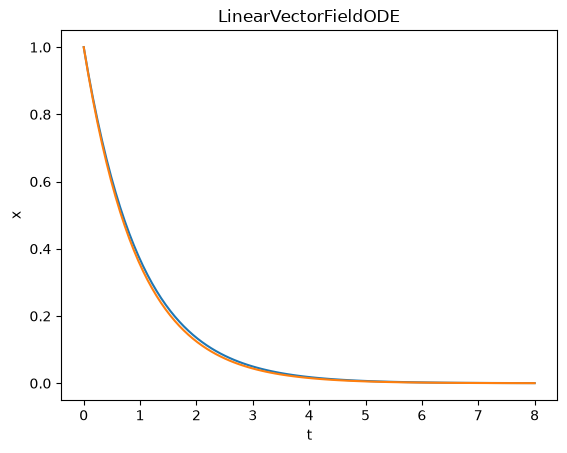

In [2]:
from generative_models.de import LinearVectorFieldODE, Euler
import torch
import matplotlib.pyplot as plt

x0 = torch.Tensor([[1.0]])    # shape (b, d)
t = torch.linspace(0, 8, 100)[None, :]   # shape (b, l)

ode = LinearVectorFieldODE(theta=1)
euler = Euler(ode=ode)

x_ref = ode.flow(x0, t) # shape (b, l, d)
x_pred = euler.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)

plt.plot(t[0], x_ref[0])
plt.plot(t[0], x_pred[0])
plt.xlabel("t")
plt.ylabel("x")
plt.title("LinearVectorFieldODE")
plt.show()

Simulate a set of trajectories (flow).

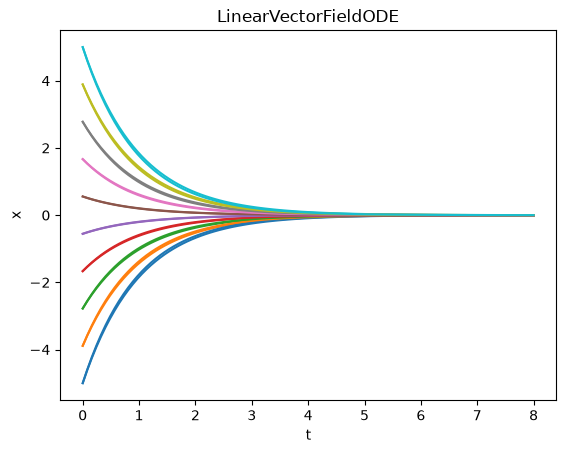

In [3]:
x0 = torch.linspace(-5, 5, 10)[:, None]   # shape (b, d)
t = torch.linspace(0, 8, 100)[None, :].expand(10, 100)   # shape (b, l)

ode = LinearVectorFieldODE(theta=1)
euler = Euler(ode=ode)

x_ref = ode.flow(x0, t) # shape (b, l, d)
x_pred = euler.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)

plt.plot(t.T, x_ref[:, :, 0].T)
plt.plot(t.T, x_pred[:, :, 0].T)
plt.xlabel("t")
plt.ylabel("x")
plt.title("LinearVectorFieldODE")
plt.show()